# HA1: C x S

C - сенсомоторная представленность, S - таксономическая специфичность (глубина в RuWordNet 2.0).

**Результаты предварительные**: финальный пересчёт будет после синхронизации Лист2 (термины, определения, C) с листом Daniil.

Данные:
- признаки: лист `Лист2`;
- синсеты: лист `Daniil`;
- гиперонимы до корня: колонка `paths_synset_ids` листа `Daniil`, снапшот в `data/ruwordnet_edges.csv`.

При `USE_LIVE_SHEET = True` листы качаются из таблицы, иначе берутся снапшоты из `data/`.

In [2]:
USE_LIVE_SHEET = True
SHEET_ID = "1H9Oi7JLhYowXhTEOvbHaJyApQGAFSvIqZ0h9pW7_QOI"

FEATURES = ["visual", "auditory", "tactile", "motor", "proprioceptive", "interoceptive", "social"]
SCALE_MAX = 2

C_METHOD = "sum"     # sum | sum_nonvisual | breadth | l2
S_PATH = "min"       # min | max | mean, если путей до корня несколько
ROOTLESS_AS_NA = False  # синсет без гиперонима: False -> S = 0, True -> S = NA
W = 0.5              # вес C в G = W*C_norm + (1-W)*S_norm, на квадранты не влияет
THRESHOLD = 0.5      # порог квадрантов: C >= 0.5 -> C+, S >= 0.5 -> S+
MIN_PER_QUADRANT = 3

import urllib.parse, urllib.request
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
DATA, FIG, OUT = Path("data"), Path("figures"), Path("results")
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

## Данные

In [3]:
def load_sheet(name, snapshot):
    path = DATA / snapshot
    if USE_LIVE_SHEET:
        url = (f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/gviz/tq?tqx=out:csv&sheet="
               + urllib.parse.quote(name))
        try:
            path.write_bytes(urllib.request.urlopen(url, timeout=20).read())
            print(f"{name}: из таблицы")
        except OSError as e:
            print(f"{name}: таблица недоступна ({e}), беру снапшот")
    return pd.read_csv(path, dtype=str)


def numbered(frame):
    frame = frame[frame["concept_id"].str.fullmatch(r"\d+", na=False)].copy()
    frame["concept_id"] = frame["concept_id"].astype(int)
    return frame


feat = numbered(load_sheet("Лист2", "features_list2.csv"))
tax_sheet = load_sheet("Daniil", "taxonomy_daniil.csv")
tax = numbered(tax_sheet)

# рёбра берём из путей на листе Daniil (колонка paths_synset_ids), csv - запасной вариант
pairs = set()
for cell in tax_sheet.get("paths_synset_ids", pd.Series(dtype=str)).dropna():
    for line in cell.splitlines():
        nodes = [n.strip() for n in line.split("->") if n.strip()]
        pairs |= set(zip(nodes, nodes[1:]))
if pairs:
    edges = pd.DataFrame(sorted(pairs), columns=["parent_id", "child_id"])
    edges.to_csv(DATA / "ruwordnet_edges.csv", index=False)
    print(f"рёбра: {len(edges)} из листа Daniil")
else:
    edges = pd.read_csv(DATA / "ruwordnet_edges.csv", dtype=str)
    print(f"рёбра: {len(edges)} из data/ruwordnet_edges.csv")

for f in FEATURES:
    feat[f] = pd.to_numeric(feat[f].str.replace(",", "."), errors="coerce")

tax["synset"] = tax["ruwordnet_synset_id"].where(tax["ruwordnet_synset_id"] != "NA")
tax["pos"] = tax["synset"].str[-1].map({"N": "noun", "A": "adj", "V": "verb"}).fillna("prep")

df = feat[["concept_id", "term", "provenance"] + FEATURES].merge(
    tax[["concept_id", "term", "synset", "pos"]], on="concept_id", suffixes=("", "_tax"))
df[["concept_id", "term", "pos", "synset"] + FEATURES]

Лист2: из таблицы
Daniil: из таблицы
рёбра: 31 из листа Daniil


,concept_id,term,pos,synset,visual,auditory,tactile,motor,proprioceptive,interoceptive,social
0,1,точка,noun,120377-N,2,0,0,0,0,0,0
1,2,линия,noun,106582-N,2,0,0,0,0,0,0
2,3,поверхность,noun,107133-N,1,0,1,0,0,0,0
3,4,граница,noun,106514-N,2,0,1,0,0,0,0
4,5,область,noun,100076-N,1,0,0,0,0,0,0
5,6,расстояние,noun,106757-N,1,0,0,0,1,0,0
6,7,высота,noun,106758-N,2,0,0,0,1,0,0
7,8,направление,noun,106586-N,2,0,0,1,1,0,0
8,9,путь,noun,183-N,1,0,0,1,1,0,0
9,10,траектория,noun,116178-N,2,0,0,1,1,0,0


In [4]:
issues = []
if df[FEATURES].isna().any().any():
    issues.append(f"пустые признаки: {list(df.loc[df[FEATURES].isna().any(axis=1), 'term'])}")
if ((df[FEATURES] < 0) | (df[FEATURES] > SCALE_MAX)).any().any():
    issues.append("значения вне шкалы 0-2")
if (df["term"] != df["term_tax"]).any():
    issues.append(f"термины не совпадают: {df.loc[df.term != df.term_tax, ['term', 'term_tax']].values.tolist()}")
if len(df) != len(feat) or len(df) != len(tax):
    issues.append(f"строк: Лист2 {len(feat)}, Daniil {len(tax)}, после склейки {len(df)}")
missing = set(df["synset"].dropna()) - set(edges["child_id"]) - set(edges["parent_id"])
if missing:
    issues.append(f"синсеты без рёбер в ruwordnet_edges.csv (получат глубину 0): {missing}")

print("\n".join(issues) or "входные данные в порядке")
print("константные признаки:", [f for f in FEATURES if df[f].nunique() == 1])
print("provenance:", df["provenance"].value_counts().to_dict())

входные данные в порядке
константные признаки: ['auditory', 'interoceptive', 'social']
provenance: {'generated': 20}


## C

Основной вариант: `C_raw = сумма признаков`, `C_norm = min-max`.
Альтернативы:
- `sum_nonvisual` - без visual, он почти у всех 2;
- `breadth` - число ненулевых каналов;
- `l2` - норма вектора признаков.

In [5]:
def minmax(s):
    s = s.astype(float)
    span = s.max() - s.min()
    return (s - s.min()) / span if span else s * 0


X = df[FEATURES]
C_RAW = {
    "sum": X.sum(axis=1),
    "sum_nonvisual": X.drop(columns="visual").sum(axis=1),
    "breadth": (X > 0).sum(axis=1),
    "l2": np.sqrt((X ** 2).sum(axis=1)),
}
C_NORM = {k: minmax(v) for k, v in C_RAW.items()}
df["C_raw"], df["C_norm"] = C_RAW[C_METHOD], C_NORM[C_METHOD]
pd.DataFrame(C_NORM).set_index(df["term"]).round(2)

,sum,sum_nonvisual,breadth,l2
term,,,,
точка,0.2,0.00,0.0,0.41
линия,0.2,0.00,0.0,0.41
поверхность,0.2,0.25,0.5,0.17
граница,0.4,0.25,0.5,0.50
область,0.0,0.00,0.0,0.00
расстояние,0.2,0.25,0.5,0.17
высота,0.4,0.25,0.5,0.50
направление,0.6,0.50,1.0,0.59
путь,0.4,0.50,1.0,0.30


## S

`S_raw` - число гиперонимических рёбер до корня. Несопоставленные концепты получают NA, не 0.

Синсет без гиперонима (сейчас это «двигаться», 106587-V) Даниил проверил: это корень глагольной
иерархии, поэтому S = 0 (`ROOTLESS_AS_NA = False`). Вариант с NA оставлен ниже для сравнения.

Считать глубину в рёбрах (корень = 0) или в узлах (корень = 1) для `S_norm` неважно:
min-max не меняется от сдвига на константу.

Нормализация по всему набору (`global`) или внутри части речи (`pos`): у существительных,
прилагательных и глаголов разные иерархии.

In [6]:
parents = edges.groupby("child_id")["parent_id"].apply(list).to_dict()


def paths_to_root(node, seen=()):
    if node in seen:
        raise ValueError(f"цикл на {node}")
    if node not in parents:
        return [[node]]
    return [[node] + p for par in parents[node] for p in paths_to_root(par, seen + (node,))]


rows = []
for cid, syn in zip(df["concept_id"], df["synset"]):
    if pd.isna(syn):
        rows.append({"concept_id": cid, "n_paths": 0, "rootless": False})
        continue
    paths = paths_to_root(syn)
    depth = [len(p) - 1 for p in paths]
    rootless = syn not in parents
    if rootless and ROOTLESS_AS_NA:
        rows.append({"concept_id": cid, "n_paths": 0, "rootless": True})
        continue
    rows.append({
        "concept_id": cid, "n_paths": len(paths), "rootless": rootless,
        "S_min": min(depth), "S_max": max(depth), "S_mean": np.mean(depth),
        "root": ", ".join(sorted({p[-1] for p in paths})),
        "path": " -> ".join(paths[0]),
    })
df = df.merge(pd.DataFrame(rows), on="concept_id")

S_NORM = {}
for agg in ["min", "max", "mean"]:
    S_NORM[f"{agg}_global"] = minmax(df[f"S_{agg}"])
    S_NORM[f"{agg}_pos"] = df.groupby("pos")[f"S_{agg}"].transform(minmax)
df["S_raw"], df["S_norm"] = df[f"S_{S_PATH}"], S_NORM[f"{S_PATH}_global"]
df[["term", "pos", "synset", "S_min", "S_max", "rootless", "S_norm", "path"]]

,term,pos,synset,S_min,S_max,rootless,S_norm,path
0,точка,noun,120377-N,3.0,3.0,False,0.6,120377-N -> 106451-N -> 147134-N -> 153782-N
1,линия,noun,106582-N,3.0,3.0,False,0.6,106582-N -> 149355-N -> 106581-N -> 106509-N
2,поверхность,noun,107133-N,3.0,3.0,False,0.6,107133-N -> 106451-N -> 147134-N -> 153782-N
3,граница,noun,106514-N,4.0,4.0,False,0.8,106514-N -> 106582-N -> 149355-N -> 106581-N -> 106509-N
4,область,noun,100076-N,4.0,4.0,False,0.8,100076-N -> 7166-N -> 106451-N -> 147134-N -> 153782-N
5,расстояние,noun,106757-N,4.0,4.0,False,0.8,106757-N -> 106515-N -> 106768-N -> 146671-N -> 153782-N
6,высота,noun,106758-N,5.0,5.0,False,1.0,106758-N -> 106757-N -> 106515-N -> 106768-N -> 146671-N...
7,направление,noun,106586-N,3.0,3.0,False,0.6,106586-N -> 106451-N -> 147134-N -> 153782-N
8,путь,noun,183-N,4.0,4.0,False,0.8,183-N -> 106586-N -> 106451-N -> 147134-N -> 153782-N
9,траектория,noun,116178-N,4.0,4.0,False,0.8,116178-N -> 106586-N -> 106451-N -> 147134-N -> 153782-N


In [7]:
# у одной части речи может быть несколько корней, тогда глубины сравнимы условно
df.dropna(subset=["root"]).groupby(["pos", "root"])["term"].agg(", ".join)

pos   root    
adj   106768-A                                               близкий, далёкий
noun  106509-N                                                 линия, граница
      153782-N    точка, поверхность, область, расстояние, высота, направл...
verb  106587-V                                              двигаться, падать
Name: term, dtype: str

## Итог: G и квадранты

In [8]:
QUADRANTS = ["C+ S+", "C+ S-", "C- S+", "C- S-"]


def quadrant(c, s, tc=THRESHOLD, ts=THRESHOLD):
    if pd.isna(s):
        return "no S"
    return f"C{'+' if c >= tc else '-'} S{'+' if s >= ts else '-'}"


df["G"] = W * df["C_norm"] + (1 - W) * df["S_norm"]
df["quadrant"] = [quadrant(c, s) for c, s in zip(df["C_norm"], df["S_norm"])]
final = df[["concept_id", "term", "pos", "C_raw", "C_norm", "S_raw", "S_norm", "G", "quadrant"]].round(3)
final.sort_values("G", ascending=False)

,concept_id,term,pos,C_raw,C_norm,S_raw,S_norm,G,quadrant
6,7,высота,noun,3,0.4,5.0,1.0,0.7,C- S+
9,10,траектория,noun,4,0.6,4.0,0.8,0.7,C+ S+
8,9,путь,noun,3,0.4,4.0,0.8,0.6,C- S+
12,13,равновесие,noun,3,0.4,4.0,0.8,0.6,C- S+
10,11,вместилище,noun,4,0.6,3.0,0.6,0.6,C+ S+
7,8,направление,noun,4,0.6,3.0,0.6,0.6,C+ S+
19,20,падать,verb,6,1.0,1.0,0.2,0.6,C+ S-
3,4,граница,noun,3,0.4,4.0,0.8,0.6,C- S+
5,6,расстояние,noun,2,0.2,4.0,0.8,0.5,C- S+
11,12,отверстие,noun,3,0.4,3.0,0.6,0.5,C- S+


In [9]:
counts = df["quadrant"].value_counts().reindex(QUADRANTS + ["no S"], fill_value=0)
short = [q for q in QUADRANTS if counts[q] < MIN_PER_QUADRANT]
print(counts.to_string())
print(f"\n>= {MIN_PER_QUADRANT} в каждом квадранте:", "да" if not short else f"нет, мало в {short}")

on_c = df.loc[df["C_norm"] == THRESHOLD, "term"].tolist()
on_s = df.loc[df["S_norm"] == THRESHOLD, "term"].tolist()
print(f"ровно на пороге (идут в '+'): C {on_c or '-'}, S {on_s or '-'}")

quadrant
C+ S+     3
C+ S-     2
C- S+    10
C- S-     2
no S      3

>= 3 в каждом квадранте: нет, мало в ['C+ S-', 'C- S-']
ровно на пороге (идут в '+'): C -, S -


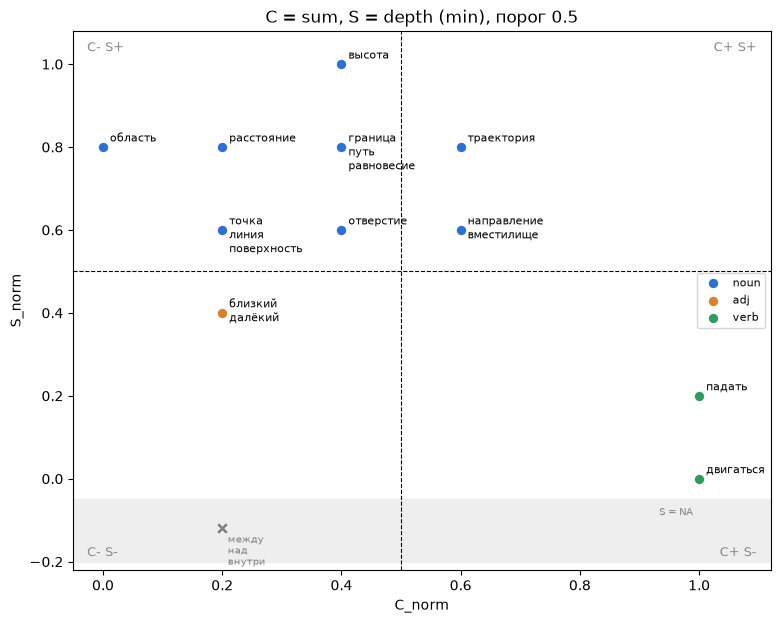

In [10]:
POS_COLORS = {"noun": "#2a6fdb", "adj": "#d9822b", "verb": "#2e9d5b"}


def scatter(ax, c, s, title, tc=THRESHOLD, ts=THRESHOLD):
    has_s = s.notna()
    for pos, color in POS_COLORS.items():
        k = has_s & (df["pos"] == pos)
        ax.scatter(c[k], s[k], s=60, color=color, label=pos, edgecolor="white", zorder=3)

    stacked = {}
    for i in df.index[has_s]:
        n = stacked.setdefault((round(c[i], 3), round(s[i], 3)), [0])
        ax.annotate(df.at[i, "term"], (c[i], s[i]), xytext=(5, 4 - 10 * n[0]),
                    textcoords="offset points", fontsize=8)
        n[0] += 1

    # концепты без S: полоса под осью
    ax.axhspan(-0.2, -0.05, color="#eee", zorder=0)
    ax.text(0.99, -0.07, "S = NA", ha="right", va="top", fontsize=7, color="grey")
    for j, i in enumerate(df.index[~has_s]):
        ax.scatter(c[i], -0.12, marker="x", color="grey", zorder=3)
        ax.annotate(df.at[i, "term"], (c[i], -0.12), xytext=(4, -10 - 8 * j),
                    textcoords="offset points", fontsize=7, color="grey")

    ax.axvline(tc, color="k", lw=0.8, ls="--")
    ax.axhline(ts, color="k", lw=0.8, ls="--")
    for x, y, label in [(0.98, 0.98, "C+ S+"), (0.02, 0.98, "C- S+"), (0.98, 0.02, "C+ S-"), (0.02, 0.02, "C- S-")]:
        ax.text(x, y, label, transform=ax.transAxes, fontsize=9, color="#888",
                ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom")
    ax.set(xlim=(-0.05, 1.12), ylim=(-0.22, 1.08), xlabel="C_norm", ylabel="S_norm", title=title)
    ax.legend(loc="center right", fontsize=8)


fig, ax = plt.subplots(figsize=(9, 7))
scatter(ax, df["C_norm"], df["S_norm"], f"C = {C_METHOD}, S = depth ({S_PATH}), порог {THRESHOLD}")
fig.savefig(FIG / "c_x_s.png", dpi=200, bbox_inches="tight")
plt.show()

### S: глобальная нормализация vs внутри части речи

Основной вариант - глобальная нормализация. При ней существительные (глубина 3-5) почти
автоматически получают S выше, чем глаголы и прилагательные (0-2). Это может быть свойством
RuWordNet, а не самих концептов.

Нормализация внутри части речи делает S сравнимой внутри группы, но сравнимость между группами
не гарантирует: максимум у каждой части речи становится 1, как бы ни была устроена её иерархия.
Ни один из вариантов не считаем правильным заранее, смотрим, насколько расходятся выводы.

In [11]:
cmp = df[["term", "pos", "S_raw", "C_norm"]].copy()
cmp["S_global"] = S_NORM[f"{S_PATH}_global"]
cmp["S_pos"] = S_NORM[f"{S_PATH}_pos"]
cmp["q_global"] = [quadrant(c, s) for c, s in zip(cmp["C_norm"], cmp["S_global"])]
cmp["q_pos"] = [quadrant(c, s) for c, s in zip(cmp["C_norm"], cmp["S_pos"])]
moved = cmp[cmp["q_global"] != cmp["q_pos"]]

print(pd.DataFrame({"global": cmp["q_global"].value_counts(), "pos": cmp["q_pos"].value_counts()})
      .reindex(QUADRANTS + ["no S"]).fillna(0).astype(int).to_string())
print(f"\nменяют квадрант: {len(moved)} из {cmp['S_global'].notna().sum()}")
cmp.round(2).sort_values(["pos", "S_raw"])

       global  pos
C+ S+       3    2
C+ S-       2    3
C- S+      10    6
C- S-       2    6
no S        3    3

меняют квадрант: 7 из 17


,term,pos,S_raw,C_norm,S_global,S_pos,q_global,q_pos
16,близкий,adj,2.0,0.2,0.4,0.0,C- S-,C- S-
17,далёкий,adj,2.0,0.2,0.4,0.0,C- S-,C- S-
0,точка,noun,3.0,0.2,0.6,0.0,C- S+,C- S-
1,линия,noun,3.0,0.2,0.6,0.0,C- S+,C- S-
2,поверхность,noun,3.0,0.2,0.6,0.0,C- S+,C- S-
7,направление,noun,3.0,0.6,0.6,0.0,C+ S+,C+ S-
10,вместилище,noun,3.0,0.6,0.6,0.0,C+ S+,C+ S-
11,отверстие,noun,3.0,0.4,0.6,0.0,C- S+,C- S-
3,граница,noun,4.0,0.4,0.8,0.5,C- S+,C- S+
4,область,noun,4.0,0.0,0.8,0.5,C- S+,C- S+


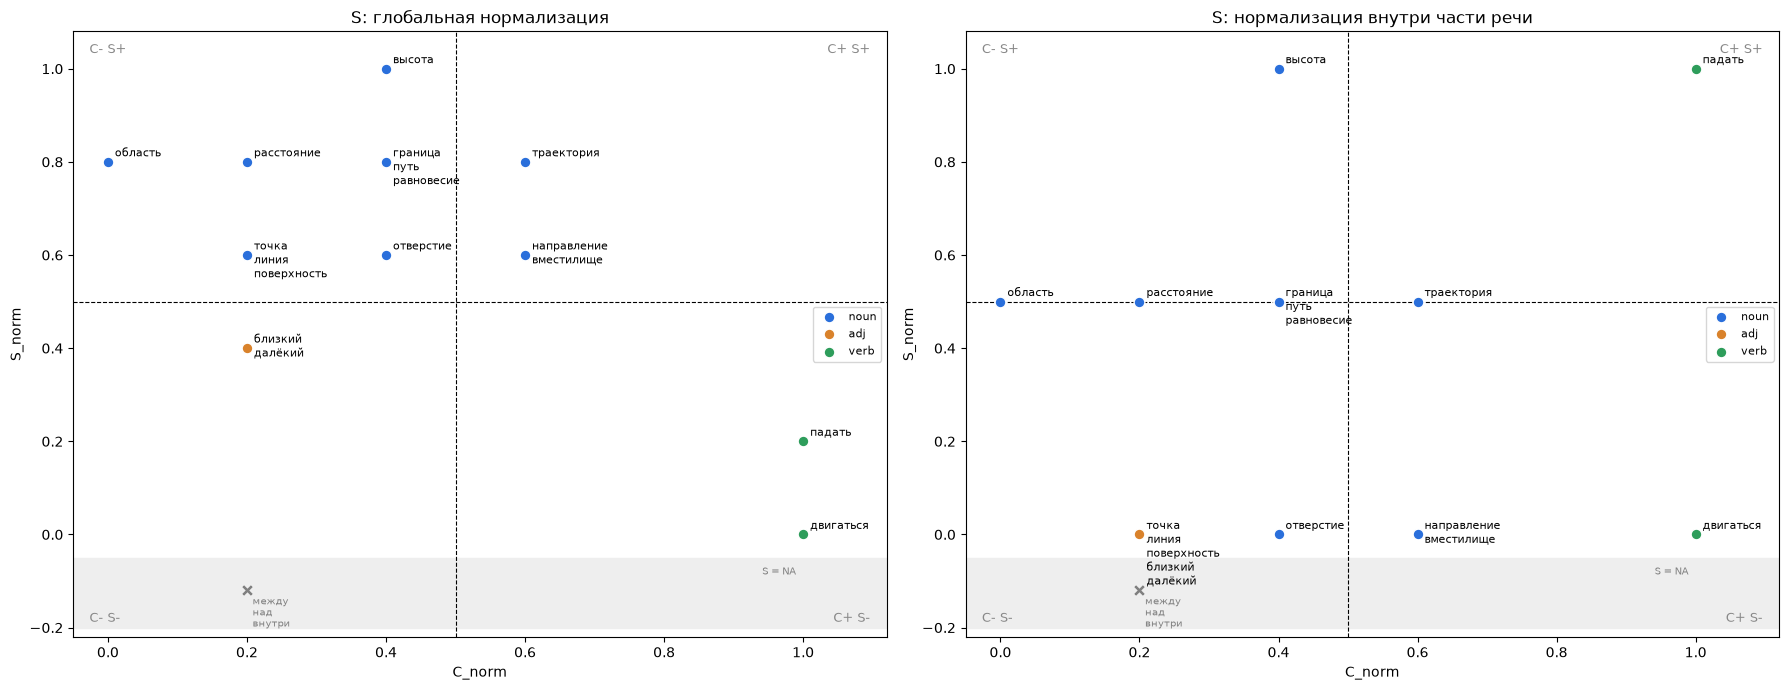

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
scatter(axes[0], df["C_norm"], cmp["S_global"], "S: глобальная нормализация")
scatter(axes[1], df["C_norm"], cmp["S_pos"], "S: нормализация внутри части речи")
plt.tight_layout()
fig.savefig(FIG / "s_global_vs_pos.png", dpi=200, bbox_inches="tight")
plt.show()

### «двигаться»: S = 0 или NA

Основной вариант S = 0 (корень). Для сравнения - что было бы при S = NA.

In [13]:
rootless_terms = df.loc[df["rootless"], "term"].tolist()
s_na = df["S_norm"].where(~df["rootless"])
q_na = pd.Series([quadrant(c, s) for c, s in zip(df["C_norm"], s_na)], index=df["term"])
print("синсеты без гиперонима:", rootless_terms or "-")
pd.DataFrame({"S = 0": df["quadrant"].value_counts(), "S = NA": q_na.value_counts()}) \
    .reindex(QUADRANTS + ["no S"]).fillna(0).astype(int)

синсеты без гиперонима: ['двигаться']


,S = 0,S = NA
C+ S+,3,3
C+ S-,2,1
C- S+,10,10
C- S-,2,2
no S,3,4


## Чувствительность к w

`w` - вес C в G, порог квадрантов - отдельный параметр, на квадранты `w` не влияет.
Смотрим ранги по G на сетке `w` и размах ранга каждого концепта.

tau Кендалла считается между G при `w = W` (опорное ранжирование) и G при каждом `w`.
В точке `w = W` tau = 1 по построению, это не подтверждение устойчивости.
Используется tau-b (`scipy.stats.kendalltau`, по умолчанию), он поправлен на совпадающие значения G.
Ранги для графика и `rank_span` - средние при совпадениях (`rank(method="average")`).

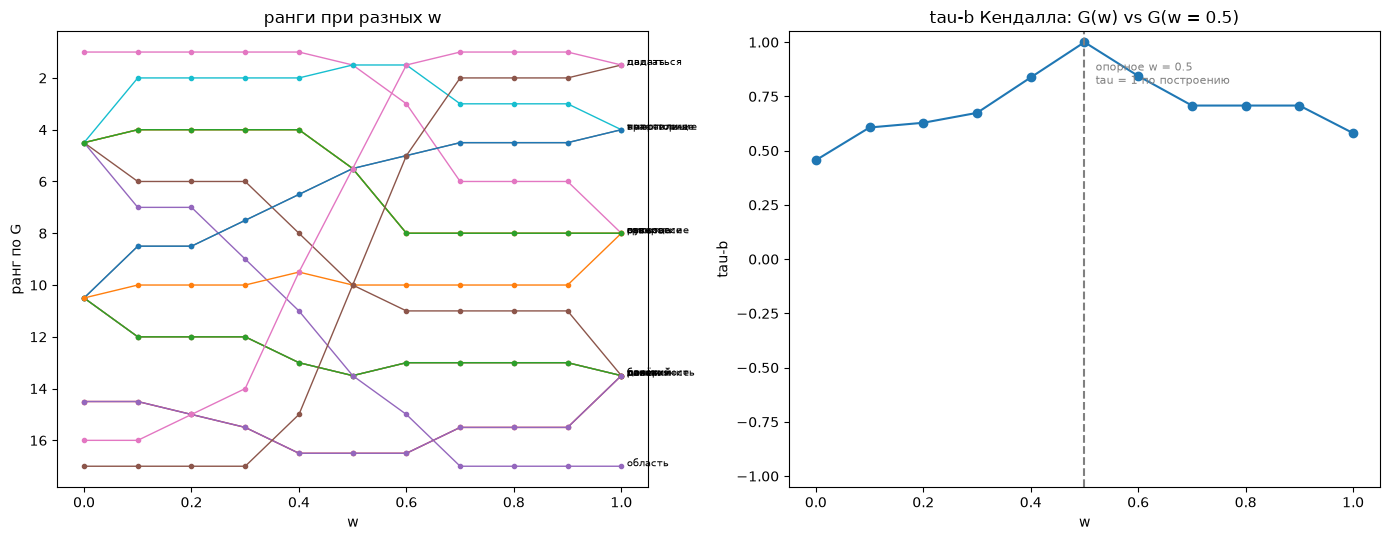

при w = 0.5: 17 концептов, 5 различных значений G (остальное - ties)
0.0    0.46
0.1    0.61
0.2    0.63
0.3    0.67
0.4    0.84
0.5    1.00
0.6    0.84
0.7    0.71
0.8    0.71
0.9    0.71
1.0    0.58


In [14]:
W_GRID = np.round(np.linspace(0, 1, 11), 2)
scored = df[df["S_norm"].notna()].set_index("term")
G_grid = pd.DataFrame({w: w * scored["C_norm"] + (1 - w) * scored["S_norm"] for w in W_GRID}).round(9)
ranks = G_grid.rank(ascending=False, method="average")
tau = pd.Series({w: kendalltau(G_grid[W], G_grid[w], variant="b")[0] for w in W_GRID}, name="tau_b")
rank_span = (ranks.max(axis=1) - ranks.min(axis=1)).rename("rank_span")
n_distinct = G_grid[W].nunique()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for term, r in ranks.iterrows():
    ax1.plot(W_GRID, r, marker=".", lw=1)
    ax1.annotate(term, (1, r[1.0]), xytext=(4, 0), textcoords="offset points", fontsize=7)
ax1.invert_yaxis()
ax1.set(xlabel="w", ylabel="ранг по G", title="ранги при разных w")
ax2.plot(W_GRID, tau, marker="o")
ax2.axvline(W, ls="--", color="grey")
ax2.annotate(f"опорное w = {W}\ntau = 1 по построению", (W, 1), xytext=(8, -30),
             textcoords="offset points", fontsize=8, color="grey")
ax2.set(xlabel="w", ylabel="tau-b", ylim=(-1.05, 1.05), title=f"tau-b Кендалла: G(w) vs G(w = {W})")
plt.tight_layout()
fig.savefig(FIG / "w_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"при w = {W}: {len(G_grid)} концептов, {n_distinct} различных значений G (остальное - ties)")
print(tau.round(2).to_string())

## Альтернативные C, S и порог

4 варианта C x 6 вариантов S x 2 порога = 48 конфигураций. Они неравноценны:

| параметр | основные (обоснованные) | экспериментальные |
|---|---|---|
| C | `sum` (исходное определение), `sum_nonvisual` (visual почти у всех 2 и не различает концепты) | `breadth` (теряет силу канала), `l2` (произвольно усиливает сильные каналы) |
| S, путь | `min`, `max` (кратчайший и длиннейший путь до корня) | `mean` (дробная глубина, смысл есть только у «падать») |
| S, нормализация | `global`, `pos` | |
| порог | `0.5` (фиксирован заранее) | `median` (делит выборку пополам по построению, близко к подгонке под баланс квадрантов) |

Конфигурация основная, если все её части основные: 2 x 4 x 1 = 8 штук.
Основную конфигурацию (`sum`, `min`, `global`, `0.5`) выбираем не по балансу квадрантов.

In [15]:
CORE = {"C": {"sum", "sum_nonvisual"}, "S": {"min_global", "max_global", "min_pos", "max_pos"},
        "thr": {"0.5"}}

scenarios = {}
for ck, sk, thr in product(C_NORM, S_NORM, ["0.5", "median"]):
    c, s = C_NORM[ck], S_NORM[sk]
    tc, ts = (THRESHOLD, THRESHOLD) if thr == "0.5" else (c.median(), s.median())
    scenarios[(ck, sk, thr)] = [quadrant(ci, si, tc, ts) for ci, si in zip(c, s)]
Q = pd.DataFrame(scenarios, index=df["term"])
Q.columns.names = ["C", "S", "thr"]

configs = Q.apply(lambda col: col.value_counts()).T.reindex(columns=QUADRANTS).fillna(0).astype(int)
configs["core"] = [ck in CORE["C"] and sk in CORE["S"] and thr in CORE["thr"] for ck, sk, thr in configs.index]
configs["balanced"] = (configs[QUADRANTS] >= MIN_PER_QUADRANT).all(axis=1)
print(f"сбалансированных: {configs.balanced.sum()} из {len(configs)}, "
      f"среди основных: {configs[configs.core].balanced.sum()} из {configs.core.sum()}")
configs[configs.balanced]

сбалансированных: 6 из 48, среди основных: 2 из 8


C+ S+  C+ S-  C- S+  C- S-   core  balanced
C             S        thr                                             
sum_nonvisual min_pos  0.5      4      3      4      6   True      True
              max_pos  0.5      4      3      4      6   True      True
              mean_pos 0.5      4      3      4      6  False      True
l2            min_pos  0.5      5      4      3      5  False      True
              max_pos  0.5      5      4      3      5  False      True
              mean_pos 0.5      5      4      3      5  False      True

In [16]:
# все основные конфигурации, первой - базовая
configs[configs.core].sort_values("balanced", ascending=False)

C+ S+  C+ S-  C- S+  C- S-  core  balanced
C             S          thr                                            
sum_nonvisual min_pos    0.5      4      3      4      6  True      True
              max_pos    0.5      4      3      4      6  True      True
sum           min_global 0.5      3      2     10      2  True     False
              min_pos    0.5      2      3      6      6  True     False
              max_global 0.5      3      2     10      2  True     False
              max_pos    0.5      2      3      6      6  True     False
sum_nonvisual min_global 0.5      5      2      8      2  True     False
              max_global 0.5      5      2      8      2  True     False

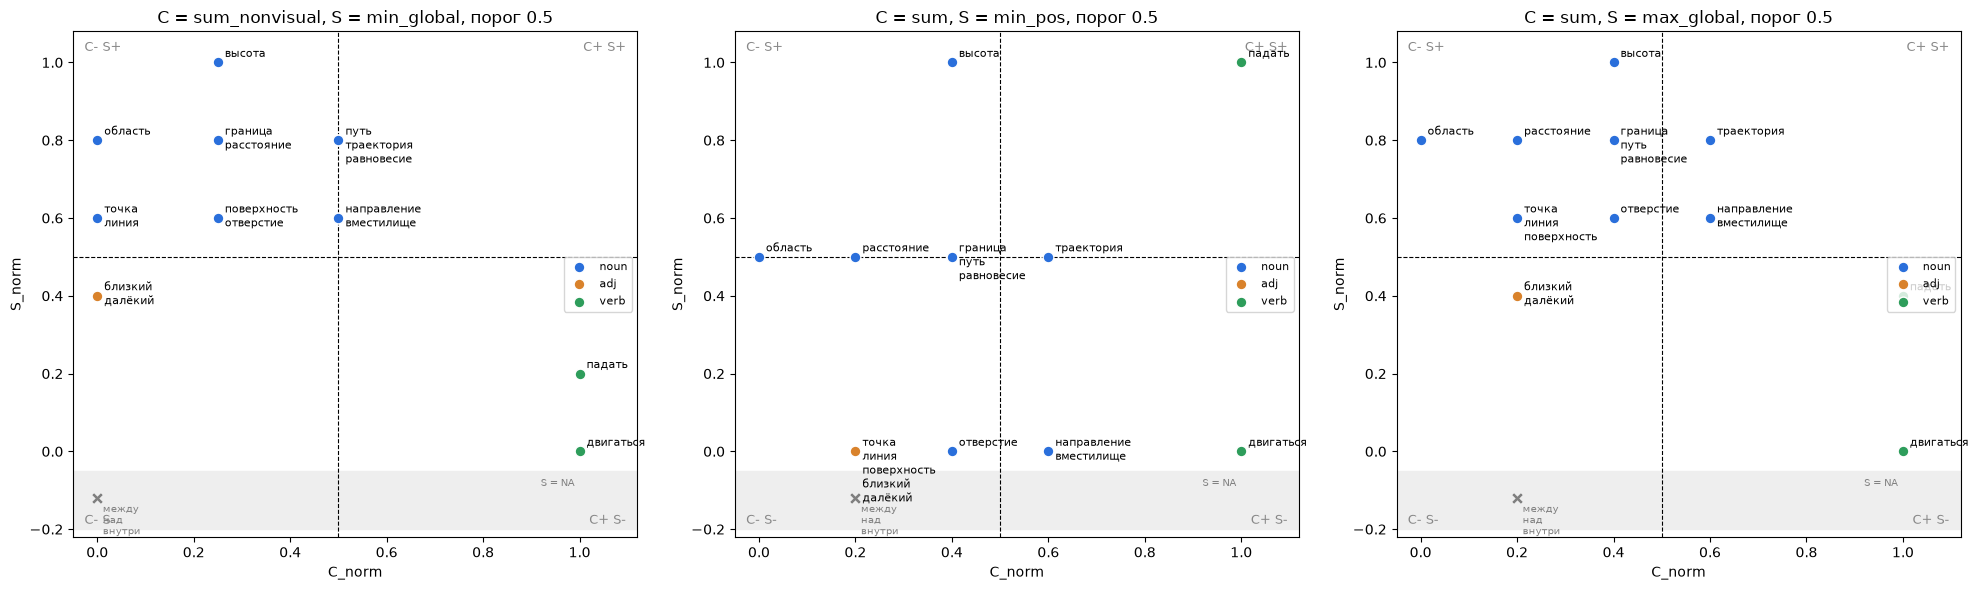

In [17]:
alts = [("sum_nonvisual", f"{S_PATH}_global", "0.5"),
        (C_METHOD, f"{S_PATH}_pos", "0.5"),
        (C_METHOD, "max_global", "0.5")]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (ck, sk, thr) in zip(axes, alts):
    scatter(ax, C_NORM[ck], S_NORM[sk], f"C = {ck}, S = {sk}, порог {thr}")
plt.tight_layout()
fig.savefig(FIG / "c_x_s_alternatives.png", dpi=200, bbox_inches="tight")
plt.show()

## Нестабильные концепты

Два типа нестабильности считаются и показываются отдельно, в один показатель не сводятся:

- **квадрант**: `q_switch` - доля конфигураций, где концепт не в базовом квадранте.
  Отдельно по всем 48 и по 8 основным. Нестабилен, если `q_switch >= 0.5`.
- **ранг**: `rank_span` - размах ранга по G на сетке `w`. Нестабилен, если `rank_span > 5`.

Например, у «двигаться» большой размах ранга, но квадрант устойчивый: при любом w
он остаётся крайним по C и по S, меняется только его место среди остальных.

In [18]:
Q_SWITCH, MAX_RANK_SPAN, NEAR = 0.5, 5, 0.1

base = df.set_index("term")["quadrant"]
core_cols = [c for c in Q.columns if configs.loc[c, "core"]]
inst = df.set_index("term")[["pos", "C_norm", "S_norm", "quadrant", "n_paths"]].copy()
inst["q_switch_all"] = 1 - Q.eq(base, axis=0).mean(axis=1)
inst["q_switch_core"] = 1 - Q[core_cols].eq(base, axis=0).mean(axis=1)
inst = inst.join(rank_span)
inst["near_threshold"] = ((inst.C_norm - THRESHOLD).abs() < NEAR) | ((inst.S_norm - THRESHOLD).abs() < NEAR)
inst = inst[inst["S_norm"].notna()]

quadrant_unstable = inst[inst.q_switch_all >= Q_SWITCH].sort_values("q_switch_all", ascending=False)
rank_unstable = inst[inst.rank_span > MAX_RANK_SPAN].sort_values("rank_span", ascending=False)
print("нестабилен квадрант:", ", ".join(quadrant_unstable.index))
print("нестабилен ранг:   ", ", ".join(rank_unstable.index))
print("оба типа:          ", ", ".join(quadrant_unstable.index.intersection(rank_unstable.index)))
inst.round(2).sort_values("q_switch_all", ascending=False)

нестабилен квадрант: отверстие, равновесие, граница, высота, путь, поверхность, падать
нестабилен ранг:    двигаться, падать, область, расстояние, высота, направление, вместилище
оба типа:           высота, падать


,pos,C_norm,S_norm,quadrant,n_paths,q_switch_all,q_switch_core,rank_span,near_threshold
term,,,,,,,,,
равновесие,noun,0.4,0.8,C- S+,1,0.88,0.5,4.0,True
отверстие,noun,0.4,0.6,C- S+,1,0.88,0.5,2.5,True
высота,noun,0.4,1.0,C- S+,1,0.75,0.0,7.0,True
граница,noun,0.4,0.8,C- S+,1,0.75,0.0,4.0,True
путь,noun,0.4,0.8,C- S+,1,0.62,0.5,4.0,True
поверхность,noun,0.2,0.6,C- S+,1,0.56,0.5,3.0,True
падать,verb,1.0,0.2,C+ S-,2,0.50,0.5,15.0,False
линия,noun,0.2,0.6,C- S+,1,0.38,0.5,3.0,True
расстояние,noun,0.2,0.8,C- S+,1,0.38,0.0,9.0,False


In [19]:
final.to_csv(OUT / "final_c_s.csv", index=False)
inst.round(3).to_csv(OUT / "instability.csv")
configs.to_csv(OUT / "configs.csv")
Q.to_csv(OUT / "quadrants_by_config.csv")
sorted(p.name for p in [*OUT.iterdir(), *FIG.iterdir()])

['c_x_s.png',
 'c_x_s_alternatives.png',
 'configs.csv',
 'figures',
 'final_c_s.csv',
 'instability.csv',
 'quadrants_by_config.csv',
 's_global_vs_pos.png',
 'w_sensitivity.png']

## Ограничения

- S - глубина в RuWordNet, и её распределение во многом задано устройством словаря.
  У существительных глубина 3-5, у прилагательных и глаголов 0-2. При глобальной нормализации
  существительные почти автоматически получают S+. При нормализации внутри части речи значения
  сравнимы внутри группы, но не между группами. Насколько квадранты отражают свойства концептов,
  а не устройство ресурса, по этим данным определить нельзя.
- У существительных два корня: `153782-N` и `106509-N` (линия, граница).
- «двигаться» (106587-V) - корень глагольной иерархии (проверено Даниилом), S = 0. Вариант с S = NA показан для сравнения.
- «между», «над» и «внутри» не нашлись в RuWordNet 2.0, поэтому S = NA. Заменять их на «промежуток», «верхний», «внутренний» нельзя: это другие концепты.
- `interoceptive` и `social` у всех равны 0, на ранги не влияют.
- Значение ровно на пороге относится к `+`: C >= 0.5 -> C+, S >= 0.5 -> S+.